# CNN para demosaicking

Se carga Kodak, se entrena la CNN base de la Figura 3, se prueban variaciones y se comparan reconstrucciones con la imagen RGB original.

In [1]:
%pip install -q tensorflow scikit-image pillow opencv-python pandas matplotlib

import os
import time
import urllib.request
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from tensorflow.keras import Model, layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

BAYER_PATTERN = "GRBG"
PATCH_SIZE = 128
BATCH_SIZE = 32
EPOCHS_BASE = 100
EPOCHS_VARIANTS = 100
LEARNING_RATE = 1e-3
RUN_VARIANTS = True
KODAK_URL = "https://arizona.box.com/shared/static/5bk6qar4vgfizmhum8onreu6sp90bz2i"
DATA_DIR = Path("/content/kodak")
if not Path("/content").exists():
    DATA_DIR = Path("kodak")
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("Fig")
RESULTS_DIR = Path("resultados")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Dispositivos:", tf.config.list_physical_devices())

TensorFlow: 2.20.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset Kodak

Se descargan las 24 imágenes, se normalizan y se separan por imagen: 20 para entrenamiento y 4 para prueba.

Imágenes: (24, 512, 768, 3)
Entrenamiento: (20, 512, 768, 3)
Prueba: (4, 512, 768, 3)


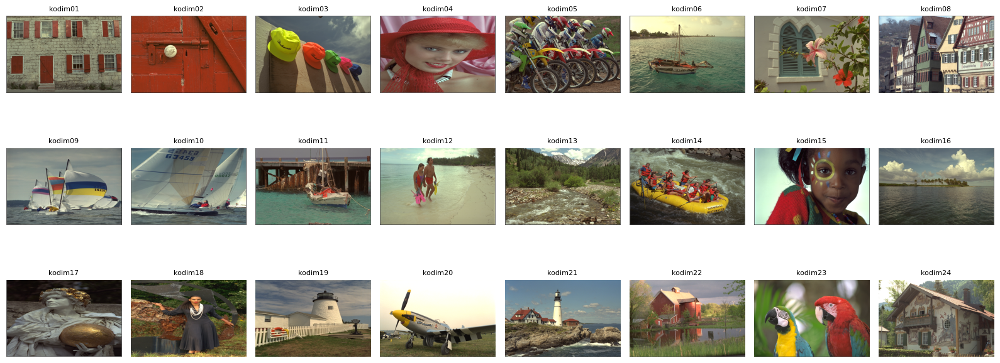

In [2]:
def download_kodak(data_dir=DATA_DIR):
    paths = sorted(data_dir.rglob("kodim*.png"))
    if len(paths) >= 24:
        return paths[:24]

    # Respaldo para ejecutar el notebook desde la raíz de este repositorio.
    local_roots = [Path("tareas/dataset"), Path("../dataset")]
    for root in local_roots:
        local_paths = list(root.glob("*.png")) if root.exists() else []
        local_paths = sorted(local_paths, key=lambda path: int(path.stem) if path.stem.isdigit() else path.stem)
        if len(local_paths) >= 24:
            return local_paths[:24]

    zip_path = data_dir / "kodak.zip"
    if not zip_path.exists():
        urllib.request.urlretrieve(KODAK_URL, zip_path)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(data_dir)
    paths = sorted(data_dir.rglob("kodim*.png"))
    if len(paths) < 24:
        raise RuntimeError(f"Se encontraron {len(paths)} imágenes Kodak")
    return paths[:24]

def load_rgb(path, shape=(512, 768)):
    image = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
    if image.shape[:2] != shape:
        image = tf.image.resize(image, shape, method="bilinear").numpy()
    return np.clip(image, 0.0, 1.0).astype(np.float32)

kodak_paths = download_kodak()
images = np.stack([load_rgb(path) for path in kodak_paths])
train_images = images[:20]
test_images = images[20:]
print("Imágenes:", images.shape)
print("Entrenamiento:", train_images.shape)
print("Prueba:", test_images.shape)

fig, axes = plt.subplots(3, 8, figsize=(16, 7))
for ax, image, path in zip(axes.flat, images, kodak_paths):
    ax.imshow(image)
    ax.set_title(path.stem, fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Muestreo Bayer y parches

Se usa el patrón GRBG del material original y se generan entradas de 64×64×4 con objetivos RGB de 128×128×3.

x_train: (480, 64, 64, 4) y_train: (480, 128, 128, 3)
x_test: (96, 64, 64, 4) y_test: (96, 128, 128, 3)


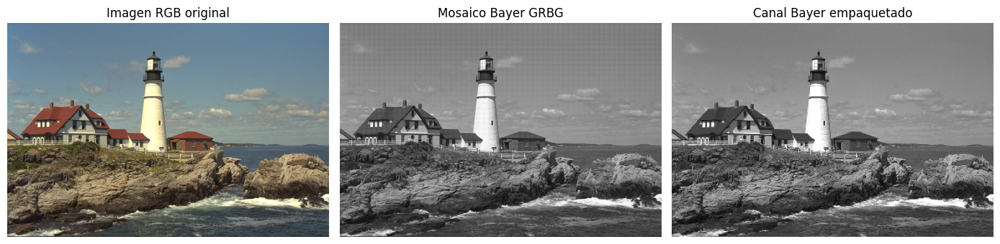

In [3]:
def bayer_cfa_kernel(shape, dtype=None):
    kernel = np.zeros(shape, dtype=np.float32)
    # GRBG: G R / B G
    kernel[0, 0, 1, 0] = 1.0
    kernel[0, 1, 0, 1] = 1.0
    kernel[1, 0, 2, 2] = 1.0
    kernel[1, 1, 1, 3] = 1.0
    return tf.convert_to_tensor(kernel, dtype=dtype or tf.float32)

def build_cfa_sampler():
    inputs = layers.Input(shape=(None, None, 3), name="rgb_input")
    outputs = layers.Conv2D(
        4, (2, 2), strides=2, use_bias=False,
        kernel_initializer=bayer_cfa_kernel, trainable=False,
        name="bayer_sampler",
    )(inputs)
    return Model(inputs, outputs, name="cfa_sampler")

def rgb_to_bayer(image):
    image = np.asarray(image, dtype=np.float32)
    height, width = image.shape[:2]
    mosaic = np.zeros((height, width), dtype=np.float32)
    mosaic[0::2, 0::2] = image[0::2, 0::2, 1]
    mosaic[0::2, 1::2] = image[0::2, 1::2, 0]
    mosaic[1::2, 0::2] = image[1::2, 0::2, 2]
    mosaic[1::2, 1::2] = image[1::2, 1::2, 1]
    return mosaic

def bayer_to_rgb_opencv(mosaic):
    mosaic_u8 = np.rint(np.clip(mosaic, 0.0, 1.0) * 255).astype(np.uint8)
    rgb = cv2.cvtColor(mosaic_u8, cv2.COLOR_BayerGR2RGB)
    return rgb.astype(np.float32) / 255.0

def make_patches(rgb_images, sampler, patch_size=PATCH_SIZE):
    targets = []
    for image in rgb_images:
        height, width = image.shape[:2]
        for top in range(0, height - patch_size + 1, patch_size):
            for left in range(0, width - patch_size + 1, patch_size):
                targets.append(image[top:top + patch_size, left:left + patch_size])
    targets = np.stack(targets).astype(np.float32)
    inputs = sampler.predict(targets, batch_size=BATCH_SIZE, verbose=0).astype(np.float32)
    return inputs, targets

cfa_sampler = build_cfa_sampler()
x_train, y_train = make_patches(train_images, cfa_sampler)
x_test, y_test = make_patches(test_images, cfa_sampler)
print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_test:", x_test.shape, "y_test:", y_test.shape)

sample = test_images[2]
sample_mosaic = rgb_to_bayer(sample)
sample_cfa = cfa_sampler.predict(sample[None], verbose=0)[0]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(sample)
axes[0].set_title("Imagen RGB original")
axes[1].imshow(sample_mosaic, cmap="gray")
axes[1].set_title("Mosaico Bayer GRBG")
axes[2].imshow(sample_cfa[..., 0], cmap="gray")
axes[2].set_title("Canal Bayer empaquetado")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## 3. CNN base de la Figura 3

Se construye el encoder-decoder original, se verifica su forma de salida y se reportan sus parámetros.

In [4]:
def residual_block(x, channels, name):
    skip = x
    x = layers.Conv2D(channels, 3, padding="same", activation="gelu", name=f"{name}_conv1")(x)
    x = layers.Conv2D(channels, 3, padding="same", name=f"{name}_conv2")(x)
    x = layers.Add(name=f"{name}_add")([skip, x])
    return layers.Activation("gelu", name=f"{name}_activation")(x)

def build_demosaic_cnn(hidden_channels=16, residual_blocks=0, name="demosaic_cnn"):
    inputs = layers.Input(shape=(None, None, 4), name="input")
    x1 = layers.Conv2D(hidden_channels, (2, 2), strides=2, activation="gelu", padding="same", name="conv2d_first")(inputs)
    x = layers.MaxPooling2D((2, 2), name="max_pooling_1")(x1)
    x2 = layers.Conv2D(hidden_channels, (3, 3), activation="gelu", padding="same", name="conv2d_32")(x)
    x3 = layers.Conv2D(hidden_channels, (3, 3), strides=2, activation="relu", padding="same", name="conv2d_16")(x2)
    x = layers.MaxPooling2D((2, 2), name="max_pooling_2")(x3)
    x = layers.Conv2D(hidden_channels, (3, 3), activation="gelu", padding="same", name="conv2d_8")(x)
    for block in range(residual_blocks):
        x = residual_block(x, hidden_channels, f"residual_{block + 1}")
    x = layers.Conv2DTranspose(hidden_channels, (3, 3), strides=2, activation="gelu", padding="same", name="deconv_16")(x)
    x = layers.Conv2DTranspose(hidden_channels, (3, 3), strides=2, activation="gelu", padding="same", name="deconv_32")(x)
    x = layers.Add(name="skip_32")([x, x2])
    x = layers.Conv2DTranspose(hidden_channels, (3, 3), strides=2, activation="gelu", padding="same", name="deconv_64")(x)
    x = layers.Add(name="skip_64")([x, x1])
    x = layers.Conv2DTranspose(4, (3, 3), strides=2, activation="gelu", padding="same", name="deconv_128_4")(x)
    x = layers.Add(name="skip_input")([x, inputs])
    x = layers.Conv2DTranspose(3, (3, 3), strides=2, activation="gelu", padding="same", name="deconv_output")(x)
    outputs = layers.Conv2D(3, (3, 3), activation="relu", padding="same", name="rgb_output")(x)
    return Model(inputs, outputs, name=name)

def model_parameter_table(model):
    rows = []
    for layer in model.layers:
        shape = getattr(layer, "output_shape", None)
        if shape is None:
            try: shape = tuple(layer.output.shape)
            except Exception: shape = ""
        rows.append({
            "layer": layer.name,
            "type": layer.__class__.__name__,
            "output_shape": str(shape),
            "parameters": layer.count_params(),
        })
    return pd.DataFrame(rows)

base_model = build_demosaic_cnn(name="cnn_base_figura_3")
base_model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE), loss="mse")
base_model.summary()
display(model_parameter_table(base_model))
print("Parámetros totales CNN base:", base_model.count_params())
assert base_model.count_params() == 14967

check_input = np.zeros((1, 128, 128, 4), dtype=np.float32)
check_output = base_model(check_input, training=False)
print("Entrada de verificación:", check_input.shape)
print("Salida de verificación:", check_output.shape)
assert tuple(check_output.shape[1:]) == (256, 256, 3)

Model: "cnn_base_figura_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, None,      │          0 │ -                 │
│                     │ None, 4)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_first        │ (None, None,      │        272 │ input[0][0]       │
│ (Conv2D)            │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling_1       │ (None, None,      │          0 │ conv2d_first[0][… │
│ (MaxPooling2D)      │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, None,      │      2,320 │ max_pooling_1[0]… │
│                     │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, None,      │      2,320 │ conv2d_32[0][0]   │
│                     │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling_2       │ (None, None,      │          0 │ conv2d_16[0][0]   │
│ (MaxPooling2D)      │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, None,      │      2,320 │ max_pooling_2[0]… │
│                     │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deconv_16           │ (None, None,      │      2,320 │ conv2d_8[0][0]    │
│ (Conv2DTranspose)   │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deconv_32           │ (None, None,      │      2,320 │ deconv_16[0][0]   │
│ (Conv2DTranspose)   │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_32 (Add)       │ (None, None,      │          0 │ deconv_32[0][0],  │
│                     │ None, 16)         │            │ conv2d_32[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deconv_64           │ (None, None,      │      2,320 │ skip_32[0][0]     │
│ (Conv2DTranspose)   │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_64 (Add)       │ (None, None,      │          0 │ deconv_64[0][0],  │
│                     │ None, 16)         │            │ conv2d_first[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deconv_128_4        │ (None, None,      │        580 │ skip_64[0][0]     │
│ (Conv2DTranspose)   │ None, 4)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_input (Add)    │ (None, None,      │          0 │ deconv_128_4[0][… │
│                     │ None, 4)          │            │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deconv_output       │ (None, None,      │        111 │ skip_input[0][0]  │
│ (Conv2DTranspose)   │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_output (Conv2D) │ (None, None,      │         84 │ deconv_output[0]… │
│                     │ None, 3)          │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,967 (58.46 KB)

 Trainable params: 14,967 (58.46 KB)

 Non-trainable params: 0 (0.00 B)

,layer,type,output_shape,parameters
0,input,InputLayer,"(None, None, None, 4)",0
1,conv2d_first,Conv2D,"(None, None, None, 16)",272
2,max_pooling_1,MaxPooling2D,"(None, None, None, 16)",0
3,conv2d_32,Conv2D,"(None, None, None, 16)",2320
4,conv2d_16,Conv2D,"(None, None, None, 16)",2320
5,max_pooling_2,MaxPooling2D,"(None, None, None, 16)",0
6,conv2d_8,Conv2D,"(None, None, None, 16)",2320
7,deconv_16,Conv2DTranspose,"(None, None, None, 16)",2320
8,deconv_32,Conv2DTranspose,"(None, None, None, 16)",2320
9,skip_32,Add,"(None, None, None, 16)",0


Parámetros totales CNN base: 14967
Entrada de verificación: (1, 128, 128, 4)
Salida de verificación: (1, 256, 256, 3)


## 4. Entrenamiento de la CNN base

Se entrena con los 480 parches Kodak y se muestran las pérdidas por época.


CNN base Figura 3 | parámetros: 14,967
Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 130ms/step - loss: 0.1884 - val_loss: 0.1595
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1449 - val_loss: 0.1178
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1110 - val_loss: 0.0973
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0970 - val_loss: 0.0880
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0893 - val_loss: 0.0835
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0851 - val_loss: 0.0794
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0796 - val_loss: 0.0728
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0727 - val_loss: 0.0671
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0599 - val_loss: 0.0450
Epoch 10/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0417 - val_loss: 0.0387
Epoch 11/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0372 - val_loss: 0.0307
Epoch 12/1

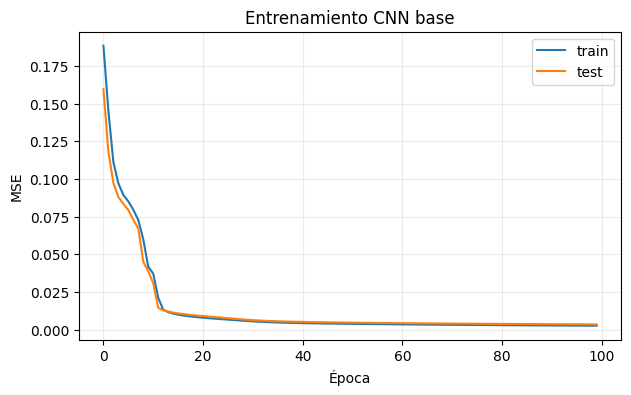

In [5]:
def make_tf_dataset(inputs, targets, training):
    dataset = tf.data.Dataset.from_tensor_slices((inputs, targets))
    if training:
        dataset = dataset.shuffle(len(inputs), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_dataset = make_tf_dataset(x_train, y_train, training=True)
test_dataset = make_tf_dataset(x_test, y_test, training=False)

def train_model(model, epochs, label):
    print(f"\n{label} | parámetros: {model.count_params():,}")
    start = time.perf_counter()
    history = model.fit(
        train_dataset,
        validation_data=test_dataset,
        epochs=epochs,
        verbose=1,
    )
    print(f"Tiempo {label}: {time.perf_counter() - start:.1f} s")
    return history

base_history = train_model(base_model, EPOCHS_BASE, "CNN base Figura 3")

def plot_history(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="test")
    plt.xlabel("Época")
    plt.ylabel("MSE")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()

plot_history(base_history, "Entrenamiento CNN base")

## 5. Prueba base y detalle ampliado

Se compara una imagen Kodak de prueba con la reconstrucción de la CNN base y una zona ampliada.

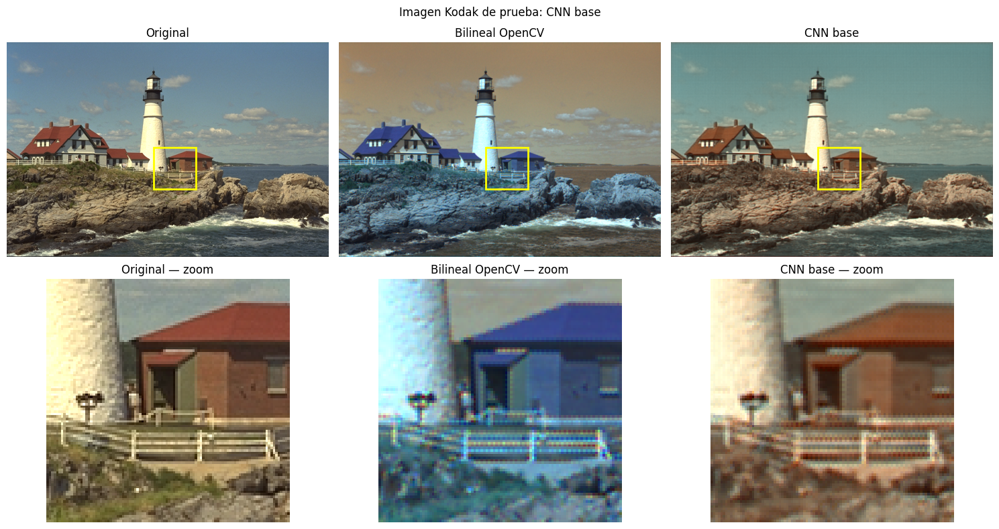

In [6]:
def reconstruct(model, image):
    cfa = cfa_sampler.predict(image[None], verbose=0)
    return np.clip(model.predict(cfa, verbose=0)[0], 0.0, 1.0)

def crop_box(image, box):
    x0, y0, x1, y1 = box
    height, width = image.shape[:2]
    return image[max(0, y0):min(height, y1), max(0, x0):min(width, x1)]

def compare_with_zoom(reference, reconstructions, box=(60, 165, 300, 365), title="Comparación", save_path=None):
    names = [("Original", reference)] + list(reconstructions.items())
    x0, y0, x1, y1 = box
    fig, axes = plt.subplots(2, len(names), figsize=(5 * len(names), 8))
    if len(names) == 1: axes = axes[:, None]
    for col, (name, image) in enumerate(names):
        axes[0, col].imshow(image)
        axes[0, col].set_title(name)
        axes[0, col].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="yellow", linewidth=2))
        axes[1, col].imshow(crop_box(image, box))
        axes[1, col].set_title(f"{name} — zoom")
        axes[0, col].axis("off")
        axes[1, col].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()

base_prediction = reconstruct(base_model, sample)
base_bilinear = bayer_to_rgb_opencv(sample_mosaic)
compare_with_zoom(
    sample,
    {"Bilineal OpenCV": base_bilinear, "CNN base": base_prediction},
    title="Imagen Kodak de prueba: CNN base",
    save_path=FIG_DIR / "cnn_kodak23_base_zoom.png",
)

## 6. Variaciones de la CNN

Se entrenan dos cambios de capacidad y se comparan contra la CNN base sobre las cuatro imágenes Kodak de prueba.


CNN 32 canales | parámetros: 57,383
Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 117ms/step - loss: 0.1998 - val_loss: 0.1695
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1431 - val_loss: 0.1117
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0992 - val_loss: 0.0801
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0729 - val_loss: 0.0626
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0561 - val_loss: 0.0478
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0428 - val_loss: 0.0362
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0283 - val_loss: 0.0191
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0163 - val_loss: 0.0155
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0142 - val_loss: 0.0144
Epoch 10/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0132 - val_loss: 0.0139
Epoch 11/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0127 - val_loss: 0.0135
Epoch 12/100


,model,parameters
0,CNN base Figura 3,14967
1,CNN 32 canales,57383
2,CNN 32 canales + residuales,131367


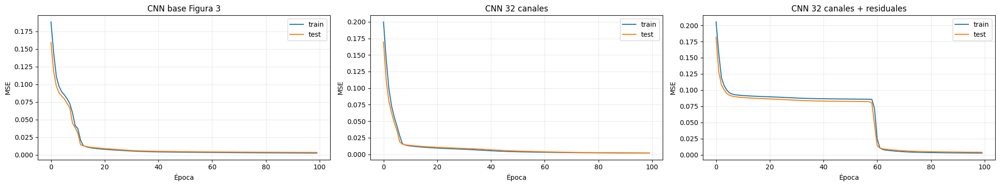

In [7]:
VARIANT_CONFIGS = [
    {"name": "CNN 32 canales", "keras_name": "cnn_32_canales", "hidden_channels": 32, "residual_blocks": 0},
    {"name": "CNN 32 canales + residuales", "keras_name": "cnn_32_canales_residuales", "hidden_channels": 32, "residual_blocks": 4},
]

models = {"CNN base Figura 3": base_model}
histories = {"CNN base Figura 3": base_history}

if RUN_VARIANTS:
    for config in VARIANT_CONFIGS:
        model = build_demosaic_cnn(
            hidden_channels=config["hidden_channels"],
            residual_blocks=config["residual_blocks"],
            name=config["keras_name"],
        )
        model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE), loss="mse")
        models[config["name"]] = model
        histories[config["name"]] = train_model(model, EPOCHS_VARIANTS, config["name"])

parameter_rows = [
    {"model": name, "parameters": model.count_params()}
    for name, model in models.items()
]
display(pd.DataFrame(parameter_rows))

fig, axes = plt.subplots(1, len(histories), figsize=(7 * len(histories), 4), squeeze=False)
for ax, (name, history) in zip(axes.flat, histories.items()):
    ax.plot(history.history["loss"], label="train")
    ax.plot(history.history["val_loss"], label="test")
    ax.set_title(name)
    ax.set_xlabel("Época")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Comparación cuantitativa y mejor CNN

Se calculan MSE, PSNR y SSIM para cada CNN y se selecciona la mejor por PSNR promedio.

In [8]:
def compute_metrics(reference, estimate):
    reference = np.clip(reference.astype(np.float32), 0.0, 1.0)
    estimate = np.clip(estimate.astype(np.float32), 0.0, 1.0)
    mse = float(np.mean((reference - estimate) ** 2))
    psnr = float(peak_signal_noise_ratio(reference, estimate, data_range=1.0))
    ssim = float(structural_similarity(reference, estimate, channel_axis=-1, data_range=1.0))
    return {"MSE": mse, "PSNR [dB]": psnr, "SSIM": ssim}

def evaluate_model(model, rgb_images):
    rows = []
    predictions = []
    for index, image in enumerate(rgb_images):
        prediction = reconstruct(model, image)
        predictions.append(prediction)
        rows.append({"imagen": index + 21, **compute_metrics(image, prediction)})
    return pd.DataFrame(rows), predictions

metric_tables = {}
predictions_by_model = {}
summary_rows = []
for name, model in models.items():
    table, predictions = evaluate_model(model, test_images)
    metric_tables[name] = table
    predictions_by_model[name] = predictions
    mean_metrics = table[["MSE", "PSNR [dB]", "SSIM"]].mean()
    summary_rows.append({"model": name, "parameters": model.count_params(), **mean_metrics.to_dict()})

results_df = pd.DataFrame(summary_rows).sort_values("PSNR [dB]", ascending=False).reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv(RESULTS_DIR / "cnn_metrics.csv", index=False)
print("Tabla guardada en:", RESULTS_DIR / "cnn_metrics.csv")
for name, table in metric_tables.items():
    print(f"\n{name}")
    display(table.round(4))

best_name = results_df.iloc[0]["model"]
best_model = models[best_name]
best_predictions = predictions_by_model[best_name]
print("Mejor CNN por PSNR promedio:", best_name)

,model,parameters,MSE,PSNR [dB],SSIM
0,CNN 32 canales,57383,0.0019,27.4779,0.8421
1,CNN base Figura 3,14967,0.0031,25.3716,0.8427
2,CNN 32 canales + residuales,131367,0.0039,24.4856,0.8075



CNN base Figura 3


,imagen,MSE,PSNR [dB],SSIM
0,21,0.0021,26.7013,0.8512
1,22,0.0024,26.2671,0.8311
2,23,0.0052,22.8198,0.8363
3,24,0.0027,25.6983,0.8522



CNN 32 canales


,imagen,MSE,PSNR [dB],SSIM
0,21,0.0018,27.4211,0.8511
1,22,0.0014,28.5388,0.8247
2,23,0.0015,28.2902,0.8568
3,24,0.0027,25.6617,0.8360



CNN 32 canales + residuales


,imagen,MSE,PSNR [dB],SSIM
0,21,0.0028,25.5795,0.7953
1,22,0.0027,25.6195,0.8024
2,23,0.0068,21.6809,0.8062
3,24,0.0031,25.0624,0.8259


Mejor CNN por PSNR promedio: CNN 32 canales


## 8. Imagen particular: original, CNN base, mejor CNN y detalle

Se observa la misma imagen de prueba con todas las CNN y con el recorte ampliado usado en la tarea 1.

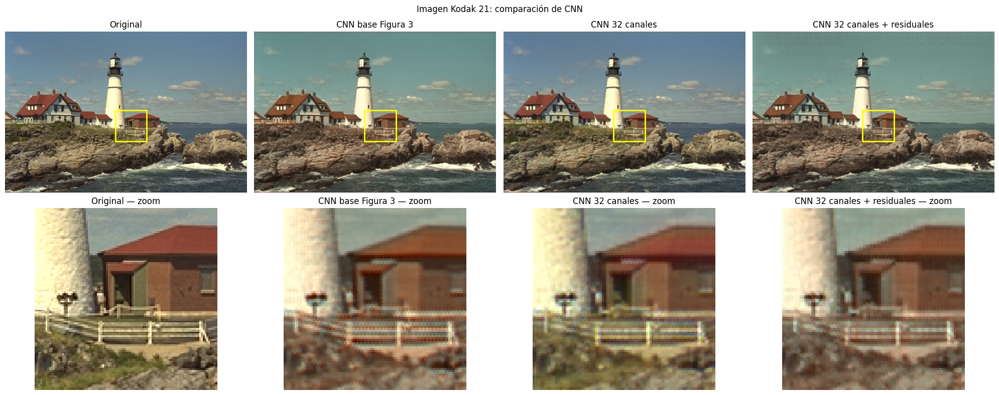

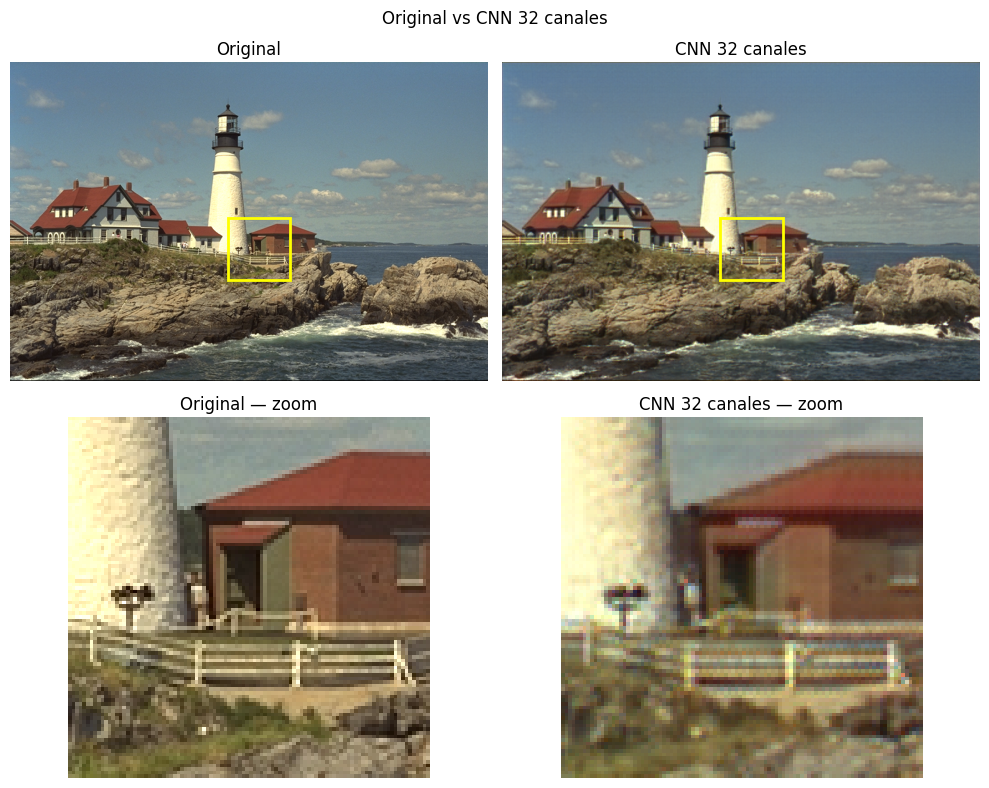

In [9]:
selected_index = 2
selected_reference = test_images[selected_index]
selected_reconstructions = {
    name: predictions[selected_index]
    for name, predictions in predictions_by_model.items()
}
compare_with_zoom(
    selected_reference,
    selected_reconstructions,
    box=(60, 165, 300, 365),
    title=f"Imagen Kodak {selected_index + 21}: comparación de CNN — cara del loro verde",
    save_path=FIG_DIR / "cnn_kodak23_variantes_zoom.png",
)

compare_with_zoom(
    selected_reference,
    {best_name: best_predictions[selected_index]},
    box=(60, 165, 300, 365),
    title=f"Original vs {best_name} — cara del loro verde",
    save_path=FIG_DIR / "cnn_kodak23_mejor_zoom.png",
)

## 9. Todas las imágenes de prueba

Se muestra la galería completa: original y reconstrucción de la mejor CNN.

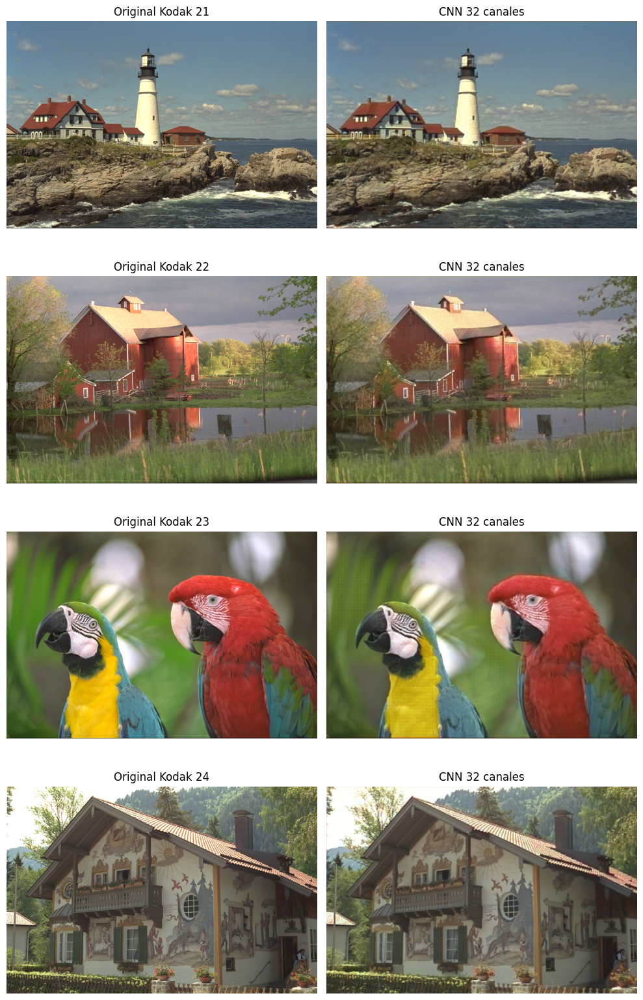

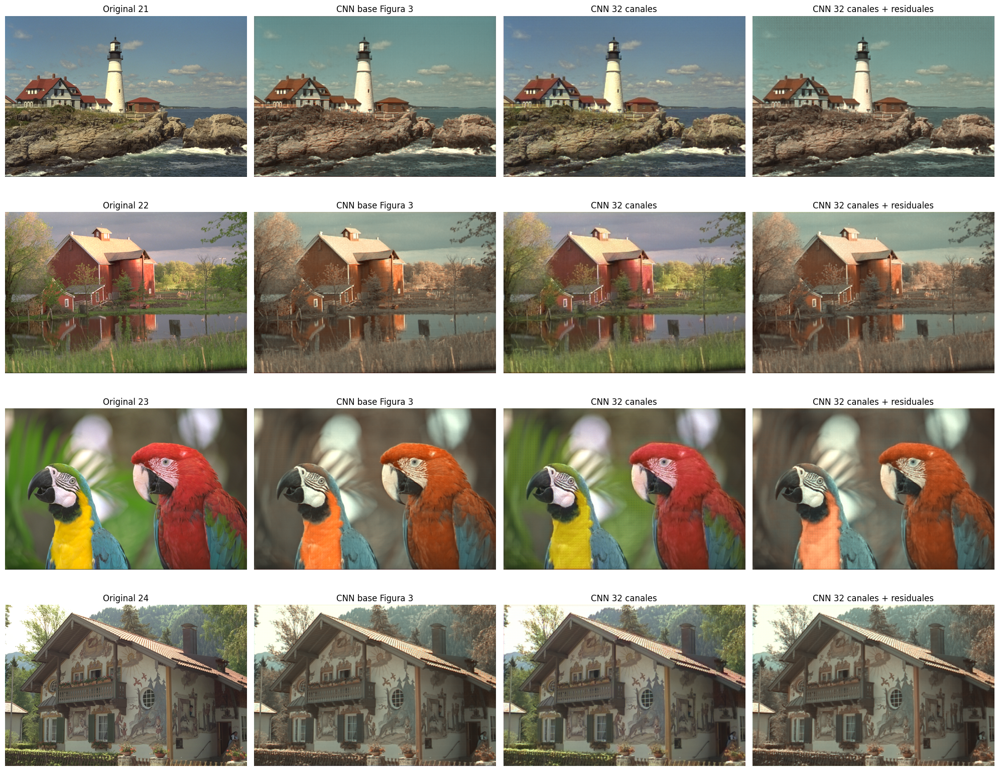

In [10]:
fig, axes = plt.subplots(len(test_images), 2, figsize=(10, 4 * len(test_images)))
if len(test_images) == 1: axes = axes[None, :]
for row, (reference, prediction) in enumerate(zip(test_images, best_predictions)):
    axes[row, 0].imshow(reference)
    axes[row, 0].set_title(f"Original Kodak {row + 21}")
    axes[row, 1].imshow(prediction)
    axes[row, 1].set_title(f"{best_name}")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "cnn_kodak23_mejor_galeria.png", dpi=180, bbox_inches="tight")
plt.show()

# Galería opcional de todas las CNN para todas las imágenes de prueba.
fig, axes = plt.subplots(len(test_images), len(models) + 1, figsize=(5 * (len(models) + 1), 4 * len(test_images)))
if len(test_images) == 1: axes = axes[None, :]
for row, reference in enumerate(test_images):
    axes[row, 0].imshow(reference)
    axes[row, 0].set_title(f"Original {row + 21}")
    axes[row, 0].axis("off")
    for col, (name, predictions) in enumerate(predictions_by_model.items(), start=1):
        axes[row, col].imshow(predictions[row])
        axes[row, col].set_title(name)
        axes[row, col].axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "cnn_kodak23_todas_las_variantes.png", dpi=180, bbox_inches="tight")
plt.show()